In [1]:
import pandas as pd

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (32940, 22)
Test shape: (8236, 20)


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## About the data

Train has 32940 rows and 22 columns. Test has 8236 rows and 20 columns.

Train and test do not have the same columns. Train has two extra columns:
- `y` — this is the answer we want to predict (yes or no).
- `duration` — how long the last phone call was.

`duration` is not in test, and we cannot know it before the call.
So I drop `duration` from the model. This is called "data leakage".

In [2]:
print("Train columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nOnly in train:")
print(set(train.columns) - set(test.columns))

print("\nOnly in test:")
print(set(test.columns) - set(train.columns))

Train columns:
['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Test columns:
['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Only in train:
{'y', 'duration'}

Only in test:
set()


In [3]:
print(train["y"].value_counts())

print("\nPercentages:")
print(train["y"].value_counts(normalize=True) * 100)

y
no     29229
yes     3711
Name: count, dtype: int64

Percentages:
y
no     88.734062
yes    11.265938
Name: proportion, dtype: float64


## Target balance

The target is not balanced:
- "no" — 88.7 %
- "yes" — only 11.3 %

This is a problem for accuracy. If the model always says "no", accuracy is 88.7 %,
but the model is useless. So I will use **ROC-AUC** to compare models.

In [4]:
print("Missing values (NaN):")
print(train.isna().sum())

print("\nUnknown values:")
print((train == "unknown").sum())

print("\nPdays values:")
print(train["pdays"].value_counts().head(10))

Missing values (NaN):
id                0
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Unknown values:
id                   0
age                  0
job                275
marital             64
education         1401
default           6871
housing            794
loan               794
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dt

In [5]:
unknown = (train == "unknown").sum()
print(unknown[unknown > 0])

print("\nPdays = 999:")
print((train["pdays"] == 999).sum())

job           275
marital        64
education    1401
default      6871
housing       794
loan          794
dtype: int64

Pdays = 999:
31694


## Missing values

There are no NaN values in the data.

But there are some special values that are like missing values:
- `"unknown"` in some columns (job, marital, education, default, housing, loan).
- `pdays = 999` in many rows. This means "client was never called before".
  It is not really 999 days.

I will handle these later in the pipeline.

In [6]:
print(train[["id", "month", "day_of_week"]].head(10))

print("\nLast 10 rows:")
print(train[["id", "month", "day_of_week"]].tail(10))

print("\nID sorted:")
print(train["id"].is_monotonic_increasing)

   id month day_of_week
0   0   may         tue
1   1   aug         mon
2   2   aug         fri
3   3   may         wed
4   4   jun         wed
5   5   aug         fri
6   6   may         thu
7   7   apr         fri
8   8   jul         wed
9   9   nov         thu

Last 10 rows:
          id month day_of_week
32930  32930   nov         fri
32931  32931   apr         thu
32932  32932   nov         thu
32933  32933   aug         mon
32934  32934   jul         tue
32935  32935   may         wed
32936  32936   jul         mon
32937  32937   may         tue
32938  32938   jul         wed
32939  32939   may         tue

ID sorted:
True


job
student          30.49
retired          25.02
unemployed       13.51
admin.           13.15
unknown          12.00
management       11.35
self-employed    10.93
technician       10.63
housemaid         9.76
entrepreneur      8.52
services          8.09
blue-collar       6.97
Name: y, dtype: float64


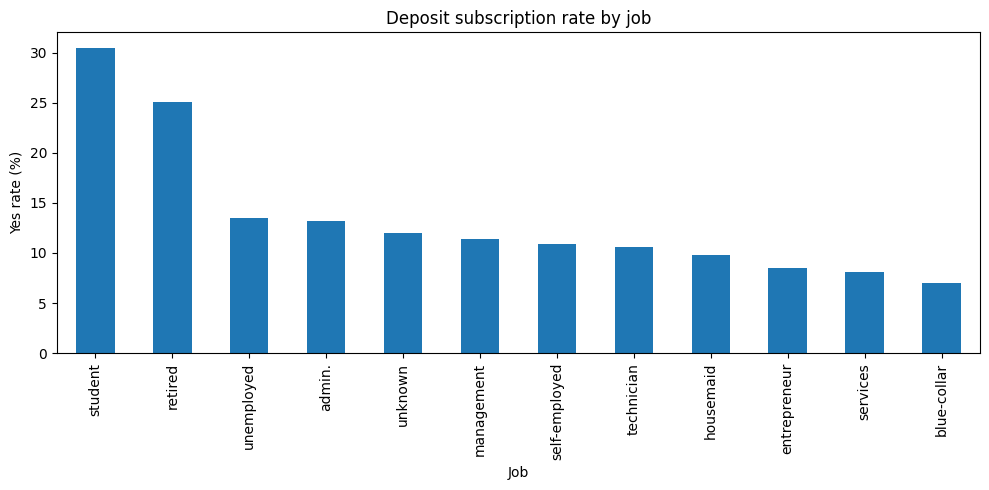

In [7]:
import matplotlib.pyplot as plt

job_rates = (
    train.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print(job_rates.round(2))

job_rates.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Yes rate (%)")
plt.xlabel("Job")
plt.title("Deposit subscription rate by job")
plt.tight_layout()
plt.show()

month
mar    51.20
dec    46.94
sep    45.25
oct    42.93
apr    20.01
jun    10.99
aug    10.43
nov    10.25
jul     9.12
may     6.35
Name: y, dtype: float64


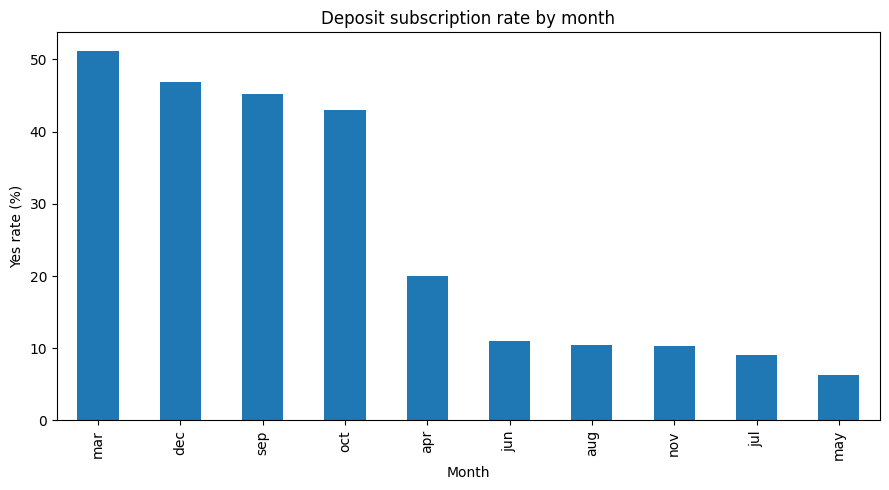

In [8]:
month_rates = (
    train.groupby("month")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print(month_rates.round(2))

month_rates.plot(kind="bar", figsize=(9, 5))
plt.xlabel("Month")
plt.ylabel("Yes rate (%)")
plt.title("Deposit subscription rate by month")
plt.tight_layout()
plt.show()

## What I see in the plots

Students (30.5 %) and retired people (25.0 %) say "yes" more often than average
(11.3 %). Blue-collar workers say "yes" very rarely (7 %).

For months: March (51 %), December (47 %) and September (45 %) have a very
high "yes" rate. June is the lowest (11 %).

So `job` and `month` look important.

In [9]:
from sklearn.model_selection import train_test_split

SEED = 2653

X = train.drop(columns=["y", "duration", "id"])
y = (train["y"] == "yes").astype(int)

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Training:", X_train.shape)
print("Hold-out:", X_holdout.shape)

print("Training yes rate:", y_train.mean())
print("Hold-out yes rate:", y_holdout.mean())

Training: (26352, 19)
Hold-out: (6588, 19)
Training yes rate: 0.11266697024893746
Hold-out yes rate: 0.11262902246508803


## Validation plan

I split train.csv into two parts:
- 80 % for training and cross-validation (X_train, y_train).
- 20 % as a hold-out (X_holdout, y_holdout). I will use it only once at the end.

For cross-validation I use **5-fold StratifiedKFold**. It keeps the same
yes/no ratio in every fold, which is important because the classes are
unbalanced.

In [11]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print(
        f"Fold {fold}:",
        f"Train = {len(train_idx)},",
        f"Validation = {len(val_idx)},",
        f"Yes rate = {y_train.iloc[val_idx].mean():.4f}"
    )

Fold 1: Train = 21081, Validation = 5271, Yes rate = 0.1127
Fold 2: Train = 21081, Validation = 5271, Yes rate = 0.1127
Fold 3: Train = 21082, Validation = 5270, Yes rate = 0.1125
Fold 4: Train = 21082, Validation = 5270, Yes rate = 0.1127
Fold 5: Train = 21082, Validation = 5270, Yes rate = 0.1127


In [12]:
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

Numeric columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
import numpy as np


def replace_pdays_sentinel(X):
    X = X.copy()
    X["pdays"] = X["pdays"].replace(999, np.nan)
    return X


pdays_transformer = Pipeline(steps=[
    ("sentinel", FunctionTransformer(replace_pdays_sentinel, validate=False)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

other_numeric = [c for c in numeric_cols if c != "pdays"]
other_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("pdays", pdays_transformer, ["pdays"]),
    ("num",   other_numeric_transformer, other_numeric),
    ("cat",   categorical_transformer, categorical_cols),
])

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED))
])

cv_results = cross_validate(
    model_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("ROC-AUC per fold:", cv_results["test_score"].round(4))
print("Mean ROC-AUC:", cv_results["test_score"].mean().round(4))
print("Std ROC-AUC:", cv_results["test_score"].std().round(4))

ROC-AUC per fold: [0.7733 0.804  0.7997 0.7818 0.7997]
Mean ROC-AUC: 0.7917
Std ROC-AUC: 0.012


In [18]:
from sklearn.impute import SimpleImputer

categorical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values="unknown"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_v2 = ColumnTransformer(transformers=[
    ("pdays", pdays_transformer, ["pdays"]),
    ("num",   other_numeric_transformer, other_numeric),
    ("cat",   categorical_transformer_v2, categorical_cols)
])

model_v2 = Pipeline(steps=[
    ("preprocessor", preprocessor_v2),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED))
])

cv_results_v2 = cross_validate(
    model_v2, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

print(f"v1 (unknown as category)   ROC-AUC = {cv_results['test_score'].mean():.4f} ± {cv_results['test_score'].std():.4f}")
print(f"v2 (unknown → most_frequent) ROC-AUC = {cv_results_v2['test_score'].mean():.4f} ± {cv_results_v2['test_score'].std():.4f}")

v1 (unknown as category)   ROC-AUC = 0.7917 ± 0.0120
v2 (unknown → most_frequent) ROC-AUC = 0.7912 ± 0.0120


## How to handle "unknown"

I tried two ways:
- **v1:** keep "unknown" as its own category. ROC-AUC = 0.7917 ± 0.0120.
- **v2:** replace "unknown" with the most frequent value. ROC-AUC = 0.7912 ± 0.0120.

The difference is very small (0.0005), much smaller than the fold spread (0.0120).
So it is inside the noise. I keep the simpler version: **v1**.

In [19]:
from sklearn.dummy import DummyClassifier

dummy_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

dummy_results = cross_validate(
    dummy_pipeline, X_train, y_train,
    cv=cv,
    scoring=["roc_auc", "accuracy"],
    n_jobs=-1
)

print("Dummy ROC-AUC per fold:", dummy_results["test_roc_auc"].round(4))
print(f"Dummy Mean ROC-AUC:  {dummy_results['test_roc_auc'].mean():.4f} ± {dummy_results['test_roc_auc'].std():.4f}")
print(f"Dummy Mean Accuracy: {dummy_results['test_accuracy'].mean():.4f} ± {dummy_results['test_accuracy'].std():.4f}")

Dummy ROC-AUC per fold: [0.5 0.5 0.5 0.5 0.5]
Dummy Mean ROC-AUC:  0.5000 ± 0.0000
Dummy Mean Accuracy: 0.8873 ± 0.0001


In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "LogReg":       LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN":          KNeighborsClassifier(),
    "DecisionTree": DecisionTreeClassifier(random_state=SEED),
    "RandomForest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
}

model_results = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    res = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    model_results[name] = res["test_score"]
    print(f"{name:15s} ROC-AUC = {res['test_score'].mean():.4f} ± {res['test_score'].std():.4f}")

LogReg          ROC-AUC = 0.7917 ± 0.0120
KNN             ROC-AUC = 0.7240 ± 0.0048
DecisionTree    ROC-AUC = 0.6271 ± 0.0093
RandomForest    ROC-AUC = 0.7724 ± 0.0118


## Compare four models

| Model | ROC-AUC (CV) |
|---|---|
| Logistic Regression | 0.7917 ± 0.0120 |
| Random Forest       | 0.7724 ± 0.0118 |
| KNN                 | 0.7240 ± 0.0048 |
| Decision Tree       | 0.6271 ± 0.0093 |

Logistic Regression is the best. Random Forest is close, but its best value
(0.7724 + 0.0118) is just below LogReg's worst value (0.7917 − 0.0120).
KNN and Decision Tree are clearly worse.

In [21]:
from sklearn.model_selection import GridSearchCV

logreg_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    logreg_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best ROC-AUC:", round(grid_search.best_score_, 4))

Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Best ROC-AUC: 0.7919


## Tuning Logistic Regression

I searched:
- `C` ∈ {0.01, 0.1, 1, 10}
- `class_weight` ∈ {None, "balanced"}

Best parameters: **C = 1**, **class_weight = "balanced"**.
CV ROC-AUC = **0.7919**.

The value with `balanced` is almost the same as without it (0.7917 vs 0.7919),
so the difference is inside the noise. But I keep `balanced`, because it makes
the model pay more attention to the small "yes" class — which matters for the
top-10 % rule.

In [22]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

comparison = results[
    results["param_classifier__C"] == 1
][[
    "param_classifier__class_weight",
    "mean_test_score",
    "std_test_score"
]]

print(comparison.to_string(index=False))

param_classifier__class_weight  mean_test_score  std_test_score
                          None         0.791702        0.011964
                      balanced         0.791946        0.011379


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=SEED, n_jobs=-1))
])

rf_param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__class_weight": [None, "balanced"]
}

rf_grid = GridSearchCV(
    rf_pipe, param_grid=rf_param_grid,
    cv=cv, scoring="roc_auc", n_jobs=-1, verbose=1
)
rf_grid.fit(X_train, y_train)

print("RF best params:", rf_grid.best_params_)
print("RF best ROC-AUC:", round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
RF best params: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
RF best ROC-AUC: 0.8008
